In [32]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import sklearn

print("numpy      ", np.__version__)
print("matplotlib ", matplotlib.__version__)
print("scikit-learn", sklearn.__version__)

numpy       2.5.3
matplotlib  3.11.2
scikit-learn 1.9.1


In [33]:
# Plot styling - cosmetic only, safe to ignore.
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["figure.dpi"] = 110

# A fixed random generator, so your numbers match the text.
# Change the seed to see different random draws.
rng = np.random.default_rng(seed=0)

In [34]:
a = np.array([1.0, 2.0, 3.0])  # 1D: a vector of 3 numbers
b = np.array(
    [
        [1.0, 2.0, 3.0],  # 2D: 2 rows, 3 columns
        [4.0, 5.0, 6.0],
    ]
)

print("a =", a)
print("a.shape =", a.shape)  # (3,)   -> 1D, length 3
print()
print("b =")
print(b)
print("b.shape =", b.shape)  # (2, 3) -> 2 rows, 3 columns

a = [1. 2. 3.]
a.shape = (3,)

b =
[[1. 2. 3.]
 [4. 5. 6.]]
b.shape = (2, 3)


In [35]:
row = np.array([[1.0, 2.0, 3.0]])          # note the double brackets
col = np.array([[1.0], [2.0], [3.0]])

print("a   shape", a.shape,   "  <- 1D, no orientation")
print("row shape", row.shape, "<- 2D, one row")
print("col shape", col.shape, "<- 2D, one column")

# reshape(-1, 1) is the idiom for "make this a single column".
# The -1 means "work the size out for me".
print()
print("a.reshape(-1, 1) shape:", a.reshape(-1, 1).shape)

a   shape (3,)   <- 1D, no orientation
row shape (1, 3) <- 2D, one row
col shape (3, 1) <- 2D, one column

a.reshape(-1, 1) shape: (3, 1)


In [36]:
# 5 examples, 2 features each.
X = rng.normal(size=(5, 2))
print(X)
print("X.shape =", X.shape, "-> 5 examples, 2 features")

[[ 0.12573022 -0.13210486]
 [ 0.64042265  0.10490012]
 [-0.53566937  0.36159505]
 [ 1.30400005  0.94708096]
 [-0.70373524 -1.26542147]]
X.shape = (5, 2) -> 5 examples, 2 features


In [37]:
x = np.array([1.0, 2.0, 3.0, 4.0])

print("x + 10  =", x + 10)        # adds 10 to every element
print("x * 2   =", x * 2)
print("x ** 2  =", x ** 2)
print("x > 2.5 =", x > 2.5)       # elementwise comparison -> array of True/False
print()
print("np.exp(x)  =", np.exp(x))  # e to the power of each element
print("np.mean(x) =", np.mean(x)) # collapses the array to one number
print("np.sum(x)  =", np.sum(x))

x + 10  = [11. 12. 13. 14.]
x * 2   = [2. 4. 6. 8.]
x ** 2  = [ 1.  4.  9. 16.]
x > 2.5 = [False False  True  True]

np.exp(x)  = [ 2.71828183  7.3890561  20.08553692 54.59815003]
np.mean(x) = 2.5
np.sum(x)  = 10.0


Here is the same computation written both ways, so you can see the speed difference
for yourself. One million numbers, squared.

In [38]:
import time

big = rng.normal(size=1_000_000)

t0 = time.perf_counter()
result_loop = [v**2 for v in big]  # the Python way
t1 = time.perf_counter()
result_vec = big**2  # the NumPy way
t2 = time.perf_counter()

print(f"Python loop : {t1 - t0:.4f} s")
print(f"NumPy       : {t2 - t1:.4f} s")
print(f"speed-up    : {(t1 - t0) / (t2 - t1):.0f}x")

Python loop : 0.0511 s
NumPy       : 0.0006 s
speed-up    : 83x


## Matrix multiplication — the `@` operator

This is the operation at the heart of every neural network, so it is worth a minute.

Matrix multiplication combines two arrays by taking **rows of the first against
columns of the second**. For each output entry, you multiply the matching numbers
pairwise and add them up.

The shape rule is the only thing you have to remember:

```
(n, k) @ (k, m)  ->  (n, m)
      ^^^^^^^  these must match; they cancel out
```

The inner numbers must be equal, and they disappear from the result.

In [39]:
A_ = np.array([[1.0, 2.0],
               [3.0, 4.0],
               [5.0, 6.0]])      # (3, 2)

B_ = np.array([[10.0, 20.0, 30.0, 40.0],
               [50.0, 60.0, 70.0, 80.0]])   # (2, 4)

C_ = A_ @ B_

print("A_ shape", A_.shape)
print("B_ shape", B_.shape)
print("C_ shape", C_.shape, " <- (3,2) @ (2,4) -> (3,4)")
print()
print(C_)

# Check one entry by hand: top-left = row 0 of A_ against column 0 of B_
print()
print("C_[0, 0] by hand:", 1.0 * 10.0 + 2.0 * 50.0, " matches", C_[0, 0])

A_ shape (3, 2)
B_ shape (2, 4)
C_ shape (3, 4)  <- (3,2) @ (2,4) -> (3,4)

[[110. 140. 170. 200.]
 [230. 300. 370. 440.]
 [350. 460. 570. 680.]]

C_[0, 0] by hand: 110.0  matches 110.0


In [40]:
X = rng.normal(size=(5, 2))    # 5 examples, 2 features
W = rng.normal(size=(2, 3))    # 2 features in, 3 units out

Z = X @ W
print("X", X.shape, "@ W", W.shape, "-> Z", Z.shape)

X (5, 2) @ W (2, 3) -> Z (5, 3)


In [41]:
Z = rng.normal(size=(5, 3))    # 5 examples, 3 units
b = np.array([100.0, 200.0, 300.0])   # one bias per unit, shape (3,)

print("Z shape", Z.shape, "+ b shape", b.shape, "->", (Z + b).shape)
print()
print(np.round(Z + b, 2))

Z shape (5, 3) + b shape (3,) -> (5, 3)

[[ 98.57 199.36 301.69]
 [ 99.4  199.88 299.79]
 [ 97.86 198.91 299.95]
 [ 99.6  200.05 297.8 ]
 [ 98.63 199.15 298.66]]


In [42]:
# The classic broadcasting trap: an array that is "the right length" but the
# wrong orientation.
try:
    Z + np.array([1.0, 2.0, 3.0, 4.0, 5.0])     # shape (5,) vs (5, 3)
except ValueError as e:
    print("ValueError:", e)

# Fix: say explicitly that it is a column, one value per example.
print()
print("as a column:", (Z + np.array([1.0, 2.0, 3.0, 4.0, 5.0]).reshape(-1, 1)).shape)

ValueError: operands could not be broadcast together with shapes (5,3) (5,) 

as a column: (5, 3)


---
# Part 2 — A single neuron

A neuron is a small function. It takes some numbers in, and puts one number out. It
does this in two steps:

**Step 1 — weighted sum.** Multiply each input by a *weight*, add them up, then add a
*bias*:

$$z = x_1 w_1 + x_2 w_2 + \dots + b$$

The weights say how much each input matters. A large positive weight means "this
input pushes the answer up"; a large negative weight means "this input pushes it
down"; a weight near zero means "ignore this input". The bias shifts the whole thing
up or down regardless of the inputs.

**Step 2 — activation.** Pass `z` through a squashing function `a = f(z)`.

The weights and the bias are the **parameters** — the numbers that get *learned*.
Everything else about the network is fixed by us in advance.

In [43]:
def neuron(x, w, b):
    """One neuron, one example.

    x: inputs,  shape (n_features,)
    w: weights, shape (n_features,)
    b: bias,    a single number

    Returns the weighted sum z (we'll add the activation in a moment).
    """
    return x @ w + b


x = np.array([2.0, 3.0])  # one example with two features
w = np.array([0.5, -1.0])  # its two weights
b = 1.0

print("z =", neuron(x, w, b))
print("by hand:", 2.0 * 0.5 + 3.0 * -1.0 + 1.0)

z = -1.0
by hand: -1.0


In [44]:
for w_try, b_try in [(np.array([0.5, -1.0]), 1.0),
                     (np.array([10.0, 0.0]), 1.0),
                     (np.array([0.5, -1.0]), -100.0)]:
    print(f"w={w_try}, b={b_try:7.1f}  ->  z = {neuron(x, w_try, b_try):8.2f}")

w=[ 0.5 -1. ], b=    1.0  ->  z =    -1.00
w=[10.  0.], b=    1.0  ->  z =    21.00
w=[ 0.5 -1. ], b= -100.0  ->  z =  -102.00


## 2.1 Activation functions

Why not stop at the weighted sum? Because a weighted sum is a *straight line*, and
stacking straight lines on top of straight lines only ever gives you another straight
line. Without a non-linear activation function, a hundred-layer network can do no
more than a single layer can. (We will demonstrate this dramatically in notebook 2.)

The activation function bends the line. Two of them cover most of what you'll meet:

**Sigmoid** squashes anything into the range 0 to 1, which makes it readable as a
probability. Large positive input → near 1. Large negative → near 0. Zero → exactly
0.5.

**ReLU** ("rectified linear unit") is almost embarrassingly simple: negatives become
zero, positives pass through unchanged. It is the default inside modern networks
because it is fast and trains well.

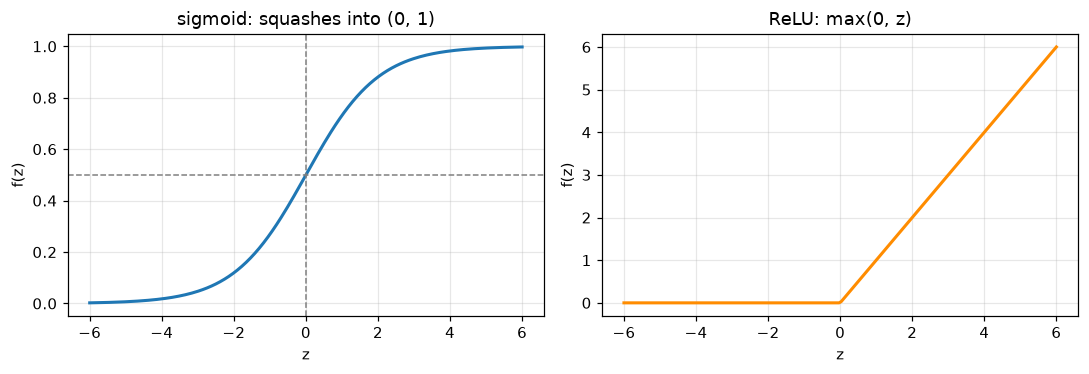

In [45]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def relu(z):
    return np.maximum(0.0, z)


zs = np.linspace(-6, 6, 200)      # 200 evenly spaced values from -6 to 6

# Two plots side by side: plt.subplots(1, 2) makes a 1-row, 2-column grid and
# hands back the figure plus an array of axes. ax.plot works like plt.plot.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].plot(zs, sigmoid(zs), linewidth=2)
axes[0].axhline(0.5, linestyle="--", linewidth=1, color="gray")
axes[0].axvline(0.0, linestyle="--", linewidth=1, color="gray")
axes[0].set_title("sigmoid: squashes into (0, 1)")
axes[0].set_xlabel("z"); axes[0].set_ylabel("f(z)")

axes[1].plot(zs, relu(zs), linewidth=2, color="darkorange")
axes[1].set_title("ReLU: max(0, z)")
axes[1].set_xlabel("z"); axes[1].set_ylabel("f(z)")

plt.tight_layout()
plt.show()

In [46]:
# Sigmoid on some specific values, to build intuition for the numbers.
for z in [-10, -2, -1, 0, 1, 2, 10]:
    print(f"sigmoid({z:4}) = {sigmoid(z):.4f}")

sigmoid( -10) = 0.0000
sigmoid(  -2) = 0.1192
sigmoid(  -1) = 0.2689
sigmoid(   0) = 0.5000
sigmoid(   1) = 0.7311
sigmoid(   2) = 0.8808
sigmoid(  10) = 1.0000


X (200, 2)  y (200,)
labels present: [0 1]


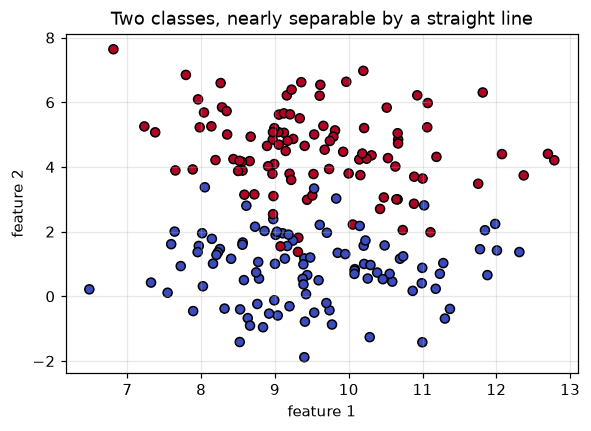

In [47]:
from sklearn.datasets import make_blobs

# Two clearly separated clusters, 2 features each.
X, y = make_blobs(
    n_samples=200, centers=2, n_features=2, cluster_std=1.2, random_state=4
)

print("X", X.shape, " y", y.shape)
print("labels present:", np.unique(y))

plt.figure()
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=35)
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title("Two classes, nearly separable by a straight line")
plt.show()

In [48]:
def plot_decision_boundary(predict_fn, X, y, title="", ax=None):
    if ax is None:
        _, ax = plt.subplots()

    # 1. Work out the area to cover: the data's range, plus a small margin.
    pad = 0.5
    x_min, x_max = X[:, 0].min() - pad, X[:, 0].max() + pad
    y_min, y_max = X[:, 1].min() - pad, X[:, 1].max() + pad

    # 2. Build a grid of points covering that area.
    # meshgrid turns two 1D ranges into two 2D coordinate arrays.
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

    # 3. Flatten the grid into a (n_points, 2) array - our usual data layout -
    # so the model can score every point in one vectorized call.
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = predict_fn(grid).reshape(xx.shape)  # reshape back into grid form

    # 4. Shade the grid, and draw a solid line at the 0.5 boundary.
    ax.contourf(xx, yy, zz, levels=50, cmap="coolwarm", alpha=0.7)
    ax.contour(xx, yy, zz, levels=[0.5], colors="k", linewidths=2)

    # 5. The real data points on top.
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=35)
    ax.set_title(title)
    ax.set_xlabel("feature 1")
    ax.set_ylabel("feature 2")
    return ax

Now let's plug in a neuron with weights we choose *by hand* — no learning yet. Just
to confirm that a neuron does indeed draw a line, and that the weights control where
it goes.

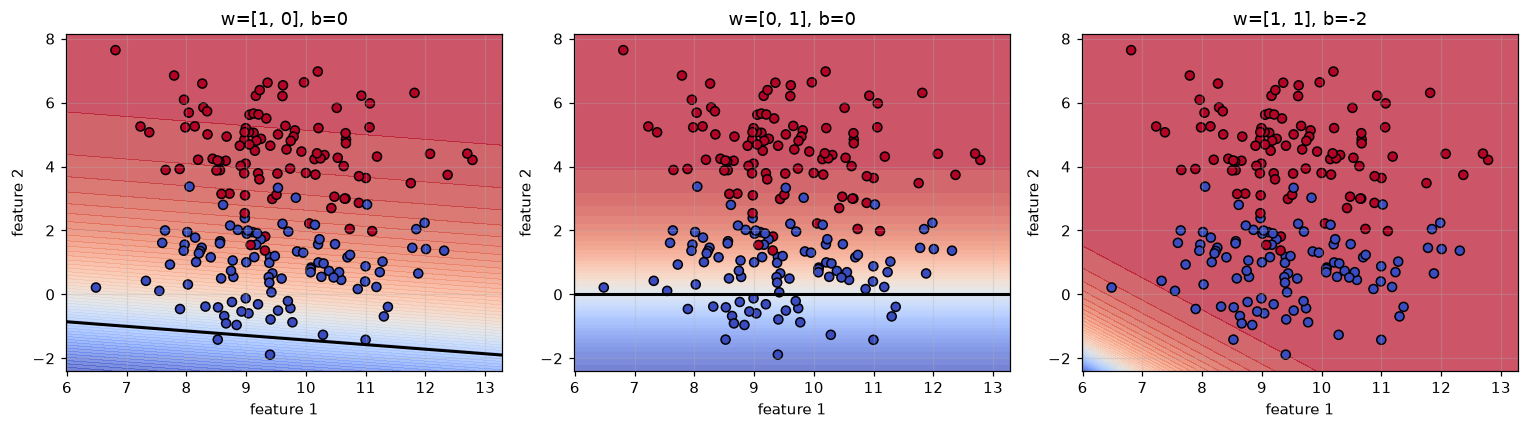

In [49]:
def neuron_predict(grid, w, b):
    return sigmoid(grid @ w + b)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

settings = [
    (np.array([0.1, 0.7]), 0.0, "w=[1, 0], b=0"),
    (np.array([0.0, 1.0]), 0.0, "w=[0, 1], b=0"),
    (np.array([1.0, 1.0]), -2.0, "w=[1, 1], b=-2")
]

for ax, (w_try, b_try, label) in zip(axes, settings):
    plot_decision_boundary(
        lambda g: neuron_predict(g, w_try, b_try), X, y, title=label, ax=ax
    )

plt.tight_layout()
plt.show()

---
# Part 3 — Learning by gradient descent

To make the computer find good weights, we need two things:

1. a **loss** — a single number that says how wrong the current weights are
2. a **rule** for changing the weights to make that number smaller

Then we repeat step 2 until the loss stops going down. That's training. All of it.

## 3.1 The loss function

A loss takes the model's predictions and the true answers, and returns one number.
Low is good.

**Mean squared error (MSE)** — average of the squared differences. The natural choice
when you're predicting a quantity (a price, a temperature).

**Binary cross-entropy (BCE)** — the right choice when you're predicting a
probability, which is our case. It is much harsher than MSE about confident mistakes:
predicting 0.99 when the answer is 0 is penalised enormously. That harshness is
exactly what you want; it keeps the model from getting confidently wrong, and it
makes training better behaved.

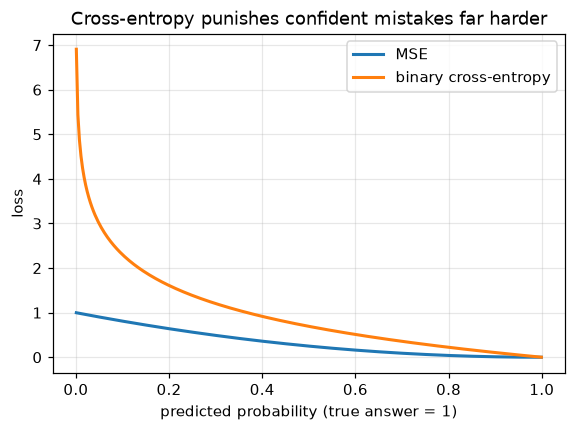

In [50]:
def mse_loss(y_pred, y_true):
    return np.mean((y_pred - y_true) ** 2)


def bce_loss(y_pred, y_true):
    # Clip away from exactly 0 and 1, otherwise log(0) = -infinity and
    # everything downstream becomes NaN.
    eps = 1e-12
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

# How each loss reacts as a prediction gets more wrong (true answer is 1).
preds = np.linspace(0.001, 0.999, 300)
truth = np.ones_like(preds)

plt.figure()
plt.plot(preds, [(p - 1.0) ** 2 for p in preds], label="MSE", linewidth=2)
plt.plot(preds, -np.log(preds), label="binary cross-entropy", linewidth=2)
plt.xlabel("predicted probability (true answer = 1)")
plt.ylabel("loss")
plt.title("Cross-entropy punishes confident mistakes far harder")
plt.legend()
plt.show()

In [51]:
y_true = np.array([1.0, 1.0, 0.0, 0.0])

for name, y_pred in [
    ("nearly right    ", np.array([0.9, 0.8, 0.2, 0.1])),
    ("unsure          ", np.array([0.5, 0.5, 0.5, 0.5])),
    ("confidently wrong", np.array([0.05, 0.1, 0.9, 0.95])),
]:
    print(
        f"{name}  MSE {mse_loss(y_pred, y_true):.3f}   BCE {bce_loss(y_pred, y_true):.3f}"
    )

nearly right      MSE 0.025   BCE 0.164
unsure            MSE 0.250   BCE 0.693
confidently wrong  MSE 0.856   BCE 2.649


## 3.2 Gradient descent in one dimension

Imagine you are standing somewhere on a hillside in thick fog. You want to reach the
bottom of the valley, but you can only see the ground at your feet. What do you do?
You feel which way is downhill, take a small step that way, and repeat.

That is gradient descent. The **gradient** is the "which way is downhill and how
steep" measurement. The **learning rate** is the size of your step.

```
new_value = old_value  -  learning_rate * gradient
```

The minus sign is there because the gradient points *uphill*, and we want to go the
other way.

Let's watch it work on a simple bowl-shaped function, `f(x) = x²`, whose gradient is
`2x`. Here we know the gradient formula, so there is no mystery — the mystery is
saved for notebook 2, where we work it out for a whole network.

In [52]:
def f(x):
    return x**2


def grad_f(x):
    return 2 * x  # the slope of x^2 at the point x


x = 8.0  # our starting point, up the side of the bowl
learning_rate = 0.1
history = [x]

for step in range(25):
    g = grad_f(x)  # which way is uphill, and how steeply
    x = x - learning_rate * g  # step the other way
    history.append(x)

print(f"start 8.000  ->  after 25 steps {x:.6f}   (the true minimum is 0)")
print("first few values:", np.round(history[:6], 3))

start 8.000  ->  after 25 steps 0.030223   (the true minimum is 0)
first few values: [8.    6.4   5.12  4.096 3.277 2.621]


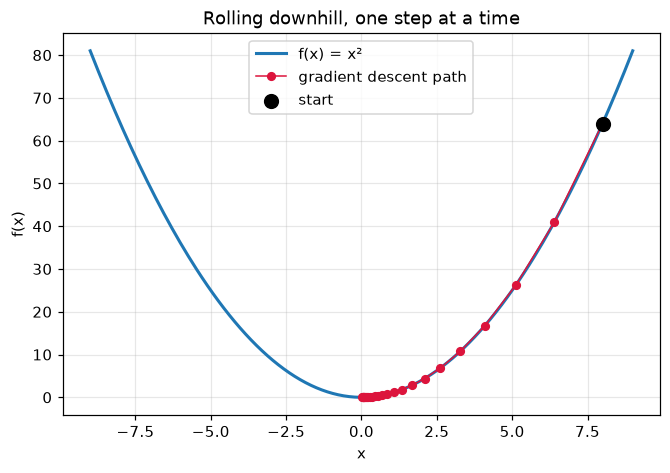

In [53]:
# Draw the bowl, and the path our steps took down it.
xs = np.linspace(-9, 9, 200)
history = np.array(history)

plt.figure(figsize=(7, 4.5))
plt.plot(xs, f(xs), linewidth=2, label="f(x) = x²")
plt.plot(history, f(history), "o-", color="crimson", markersize=5,
         linewidth=1, label="gradient descent path")
plt.scatter([history[0]], [f(history[0])], color="black", zorder=5, s=80,
            label="start")
plt.xlabel("x"); plt.ylabel("f(x)")
plt.title("Rolling downhill, one step at a time")
plt.legend()
plt.show()

## 3.3 The learning rate

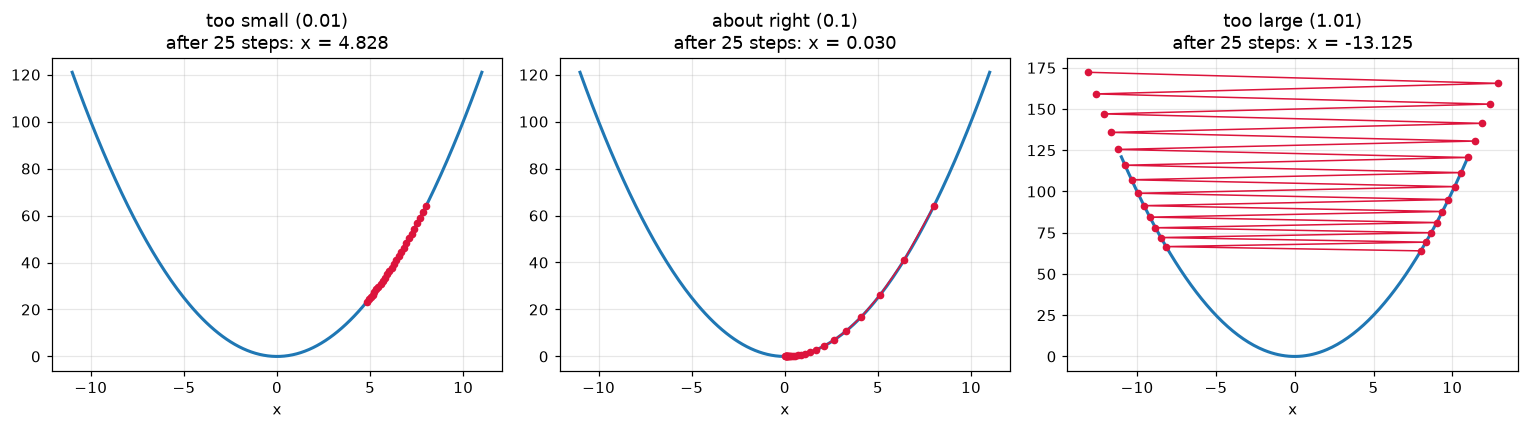

In [54]:
def descend(lr, steps=25, start=8.0):
    x, hist = start, [start]
    for _ in range(steps):
        x = x - lr * grad_f(x)
        hist.append(x)
    return np.array(hist)


fig, axes = plt.subplots(1, 3, figsize=(14, 4))
xs = np.linspace(-11, 11, 200)

for ax, (lr, label) in zip(
    axes,
    [
        (0.01, "too small (0.01)"),
        (0.10, "about right (0.1)"),
        (1.01, "too large (1.01)"),
    ],
):
    h = descend(lr)
    ax.plot(xs, f(xs), linewidth=2)
    ax.plot(h, f(h), "o-", color="crimson", markersize=4, linewidth=1)
    ax.set_title(f"{label}\nafter 25 steps: x = {h[-1]:.3f}")
    ax.set_xlabel("x")

plt.tight_layout()
plt.show()

## 3.4 Training a real neuron

In [55]:
def train_neuron(X, y, learning_rate=0.1, n_steps=200):
    """Train one sigmoid neuron with gradient descent. Returns w, b, loss history."""
    n_samples, n_features = X.shape

    rng_local = np.random.default_rng(0)
    w = rng_local.normal(size=n_features) * 0.01
    b = 0.0

    losses = []
    for step in range(n_steps):
        # ---- forward pass: what does the model currently predict? ----
        z = X @ w + b  # (n_samples,)
        y_pred = sigmoid(z)  # (n_samples,) probabilities
        losses.append(bce_loss(y_pred, y))

        # ---- backward pass: which way is downhill? ----
        error = y_pred - y  # (n_samples,)
        grad_w = (X.T @ error) / n_samples  # (n_features,)
        grad_b = np.mean(error)  # scalar

        # ---- update: take a step downhill ----
        w = w - learning_rate * grad_w
        b = b - learning_rate * grad_b

    return w, b, np.array(losses)

y_f = y.astype(float)
w_trained, b_trained, losses = train_neuron(X, y_f, learning_rate=0.5, n_steps=300)

print("learned w = ", np.round(w_trained, 3))
print("learned b =", round(b_trained, 3))
print(f"loss: {losses[0]:.4f} at the very start  ->  {losses[-1]:.4f} at the end")

learned w =  [-0.912  3.934]
learned b = -0.933
loss: 0.6943 at the very start  ->  0.1966 at the end


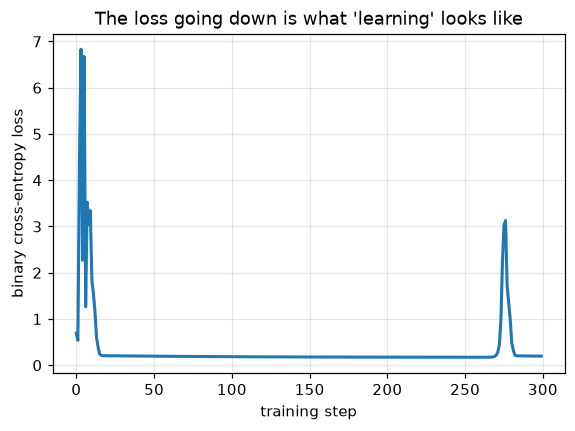

In [56]:
plt.figure()
plt.plot(losses, linewidth=2)
plt.xlabel("training step"); plt.ylabel("binary cross-entropy loss")
plt.title("The loss going down is what 'learning' looks like")
plt.show()

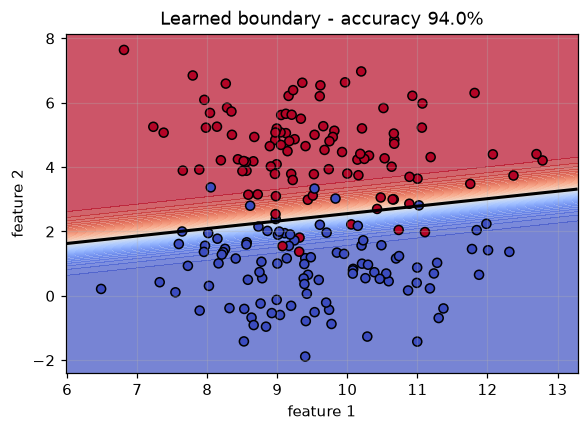

In [57]:
preds = sigmoid(X @ w_trained + b_trained)
accuracy = np.mean((preds > 0.5) == y)

plot_decision_boundary(lambda g: sigmoid(g @ w_trained + b_trained),
                       X, y, title=f"Learned boundary - accuracy {accuracy:.1%}")
plt.show()

## 3.5 Experiments

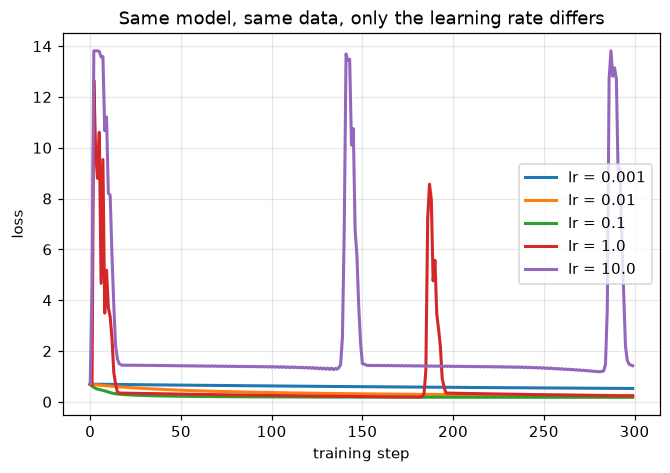

In [58]:
# Experiment 1: learning rate, on the real problem this time.
plt.figure(figsize=(7, 4.5))
for lr   in [0.001, 0.01, 0.1, 1.0, 10.0]:
    _, _, l = train_neuron(X, y_f, learning_rate=lr, n_steps=300)
    plt.plot(l, label=f"lr = {lr}", linewidth=2)

plt.xlabel("training step"); plt.ylabel("loss")
plt.title("Same model, same data, only the learning rate differs")
plt.legend()
plt.show() 

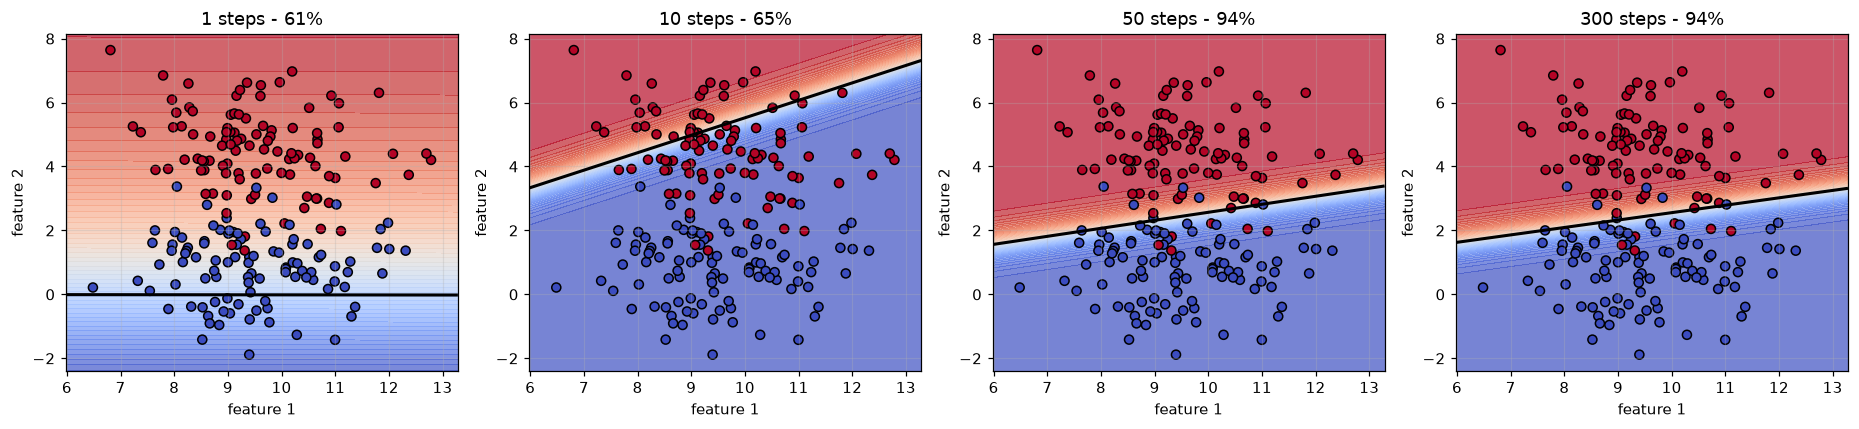

In [59]:
# Experiment 2: how long do we need to train?
fig, axes = plt.subplots(1, 4, figsize=(17, 4))

for ax, n in zip(axes, [1, 10, 50, 300]):
    w_n, b_n, _ = train_neuron(X, y_f, learning_rate=0.5, n_steps=n)
    acc = np.mean((sigmoid(X @ w_n + b_n) > 0.5) == y)
    plot_decision_boundary(lambda g, w_=w_n, b_=b_n: sigmoid(g @ w_ + b_),
                           X, y, title=f"{n} steps - {acc:.0%}", ax=ax)

plt.tight_layout()
plt.show()